# 03b SAT Reversibility #

In [1]:
%load_ext autoreload
%autoreload 2
    
import os
import sys
from dask.distributed import Client
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib import cm
import cartopy.crs as ccrs
import warnings
warnings.filterwarnings('ignore')

sys.path.append('/home/563/sc1326/repos/cdrmip_extremes')
from cdrmip_extremes.configs import data_dir, models, expts, colour_dict
from cdrmip_extremes import load_data, sat, utils, stats, regions

In [2]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

## Load data ##

In [3]:
tas_anom = load_data.load_tas_anom()

In [4]:
gwl_years = load_data.load_gwl_years()

In [5]:
gsat = load_data.load_gsat()

In [6]:
gsat

{'ACCESS-ESM1-5': <xarray.DataArray 'gsat' (time: 9360)> Size: 75kB
 [9360 values with dtype=float64]
 Coordinates:
   * time     (time) object 75kB 0000-01-31 00:00:00 ... 0779-12-31 00:00:00,
 'CanESM5': <xarray.DataArray 'gsat' (time: 5280)> Size: 42kB
 [5280 values with dtype=float64]
 Coordinates:
   * time     (time) object 42kB 0000-01-31 00:00:00 ... 0439-12-31 00:00:00,
 'CESM2': <xarray.DataArray 'gsat' (time: 4080)> Size: 33kB
 [4080 values with dtype=float64]
 Coordinates:
   * time     (time) object 33kB 0000-01-31 00:00:00 ... 0339-12-31 00:00:00,
 'CNRM-ESM2-1': <xarray.DataArray 'gsat' (time: 4080)> Size: 33kB
 [4080 values with dtype=float64]
 Coordinates:
   * time     (time) object 33kB 0000-01-31 00:00:00 ... 0339-12-31 00:00:00,
 'GFDL-ESM4': <xarray.DataArray 'gsat' (time: 4080)> Size: 33kB
 [4080 values with dtype=float64]
 Coordinates:
   * time     (time) object 33kB 0000-01-31 00:00:00 ... 0339-12-31 00:00:00,
 'MIROC-ES2L': <xarray.DataArray 'gsat' (time: 770

In [7]:
areacella, mask_land, mask_ocean = load_data.load_fx()

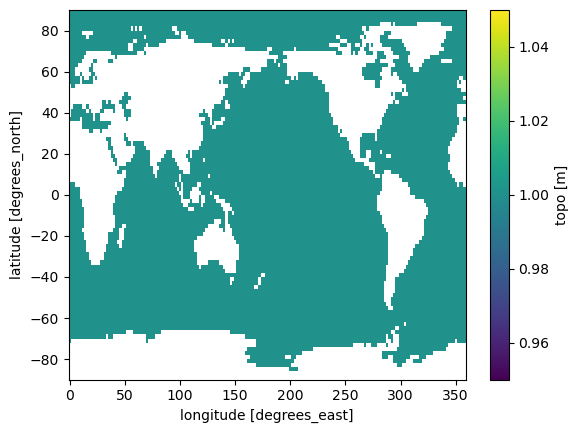

In [8]:
mask_land.topo.plot()

## Calculate rolling GSAT and peaks

In [9]:
gsat_rolling = {
    model: utils.rolling(
        ds.groupby('time.year').mean(dim='time'),
        21
    ) for model, ds in gsat.items()
}

tas_rolling = {
    model: utils.rolling(
        ds.groupby('time.year').mean(dim='time'),
        21
    ) for model, ds in tas_anom.items()
}

peaks = {
    model: dict(zip(['peak', 'peak_year'], utils.peak_warming(ds)))
    for model, ds in gsat_rolling.items()
}

In [10]:
peaks

{'ACCESS-ESM1-5': {'peak': 4.4, 'peak_year': 152},
 'CanESM5': {'peak': 6.65, 'peak_year': 150},
 'CESM2': {'peak': 5.35, 'peak_year': 150},
 'CNRM-ESM2-1': {'peak': 5.46, 'peak_year': 147},
 'GFDL-ESM4': {'peak': 3.76, 'peak_year': 150},
 'MIROC-ES2L': {'peak': 3.65, 'peak_year': 145},
 'NorESM2-LM': {'peak': 3.47, 'peak_year': 148},
 'UKESM1-0-LL': {'peak': 6.71, 'peak_year': 149}}

## Perform linear regression of local SAT against GSAT pre and post peak warming

In [67]:
def compute_patterns(data, gsat_rolling, peaks, start=None, end=None):
    patterns = {}

    for model, ds in data.items():
        ds = ds.tas

        peak_year = peaks[model]['peak_year']

        if start == 'peak':
            start = peak_year
        if end == 'peak':
            end = peak_year

        Y = ds.sel(year=slice(start, end))
        X = gsat_rolling[model].sel(year=slice(start, end))

        slope, r2 = stats.regress_pattern_with_r2(X, Y, time_dim='year')
        patterns[model] = {'slope':slope,'r2':r2}

    return patterns

In [68]:
pre_patterns = compute_patterns(
    tas_rolling,
    gsat_rolling,
    peaks,
    end='peak'
)

post_patterns = compute_patterns(
    tas_rolling,
    gsat_rolling,
    peaks,
    start='peak',
    end=280
)

In [39]:
differences = {
    model: post_patterns[model]['slope'] - pre_patterns[model]['slope'] for model in models
}

## Plot

In [ ]:
def plot_pattern(expt,period,patterns,var):
    fig, axes = plt.subplots(
        2, 4,
        figsize=(16, 6),
        subplot_kw={'projection': ccrs.Robinson()}
    )
    
    levels = np.linspace(0,2,17)
    cmap = cm.RdBu_r
    norm = BoundaryNorm(levels, ncolors=cmap.N, clip=True)
    
    
    
    for (model,ds_dict), ax in zip(patterns.items(),axes.flat):
        ds = ds_dict[var]
        im = ax.imshow(
            ds,
            transform=ccrs.PlateCarree(),
            cmap=cmap,
            norm=norm,
            origin='lower',
            extent=(0, 360, -90, 90),
        )
        ax.coastlines()
        ax.set_title(model, fontsize=16)
    
    cbar_ax = fig.add_axes([0.1, -0.05, 0.8, 0.04])
    cbar = fig.colorbar(
        plt.cm.ScalarMappable(norm=norm, cmap=cmap),
        cax=cbar_ax,
        orientation="horizontal",
        extend="both"
    )
    cbar.set_label('Local GSAT dependence (°C/°C)', fontsize=14)
    # cbar.set_ticks([-1,-0.5,0,0.5,1])
    cbar.ax.tick_params(labelsize=12)
    
    fig.suptitle(f"{expt} {period} warming regressions {var}",fontsize=24)
    
    fig.tight_layout()

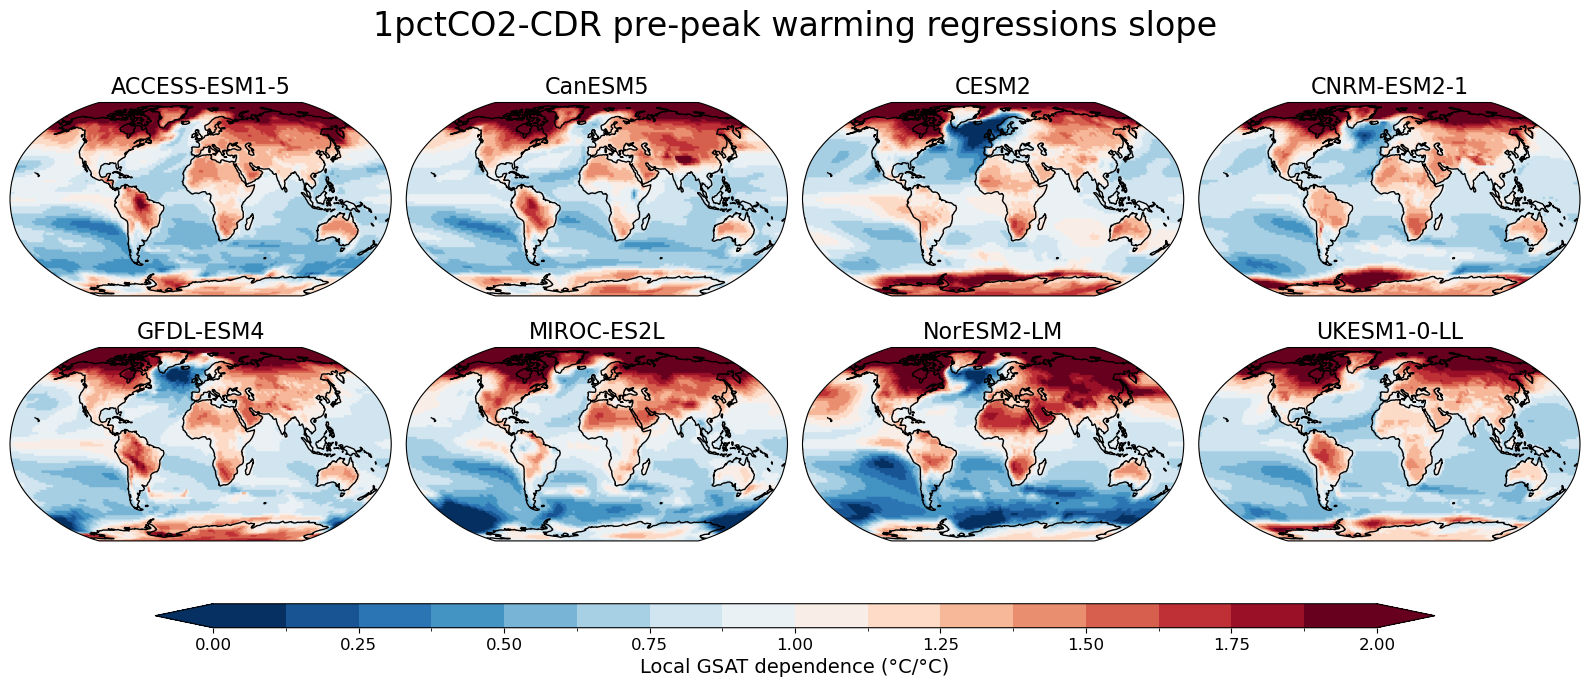

In [43]:
expt = '1pctCO2-CDR'
period = 'pre-peak'
patterns = pre_patterns
var = 'slope'
fig, axes = plt.subplots(
    2, 4,
    figsize=(16, 6),
    subplot_kw={'projection': ccrs.Robinson()}
)

levels = np.linspace(0,2,17)
cmap = cm.RdBu_r
norm = BoundaryNorm(levels, ncolors=cmap.N, clip=True)



for (model,ds_dict), ax in zip(patterns.items(),axes.flat):
    ds = ds_dict[var]
    im = ax.imshow(
        ds,
        transform=ccrs.PlateCarree(),
        cmap=cmap,
        norm=norm,
        origin='lower',
        extent=(0, 360, -90, 90),
    )
    ax.coastlines()
    ax.set_title(model, fontsize=16)

cbar_ax = fig.add_axes([0.1, -0.05, 0.8, 0.04])
cbar = fig.colorbar(
    plt.cm.ScalarMappable(norm=norm, cmap=cmap),
    cax=cbar_ax,
    orientation="horizontal",
    extend="both"
)
cbar.set_label('Local GSAT dependence (°C/°C)', fontsize=14)
# cbar.set_ticks([-1,-0.5,0,0.5,1])
cbar.ax.tick_params(labelsize=12)

fig.suptitle(f"{expt} {period} warming regressions {var}",fontsize=24)

fig.tight_layout()

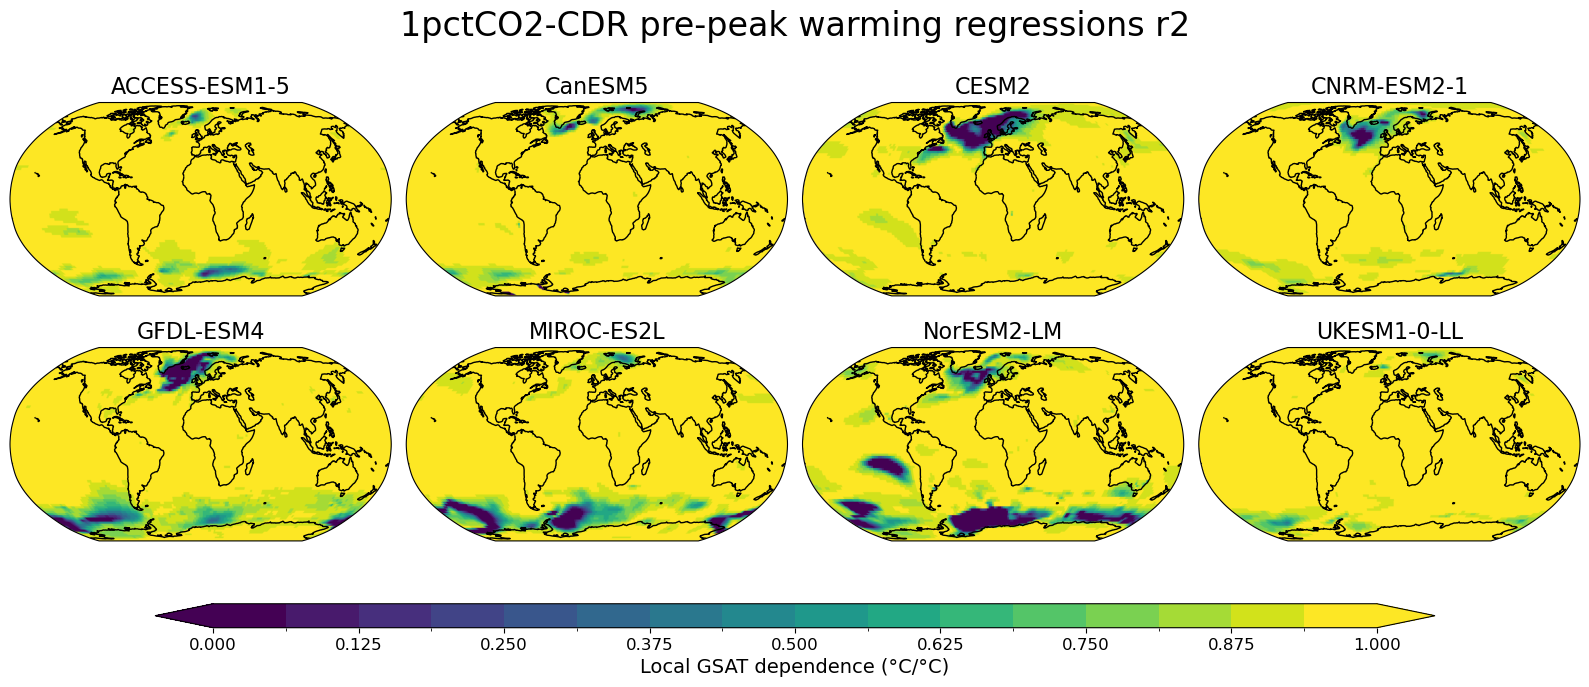

In [50]:
expt = '1pctCO2-CDR'
period = 'pre-peak'
patterns = pre_patterns
var = 'r2'
fig, axes = plt.subplots(
    2, 4,
    figsize=(16, 6),
    subplot_kw={'projection': ccrs.Robinson()}
)

levels = np.linspace(0,1,17)
cmap = cm.viridis
norm = BoundaryNorm(levels, ncolors=cmap.N, clip=True)



for (model,ds_dict), ax in zip(patterns.items(),axes.flat):
    ds = ds_dict[var]
    im = ax.imshow(
        ds,
        transform=ccrs.PlateCarree(),
        cmap=cmap,
        norm=norm,
        origin='lower',
        extent=(0, 360, -90, 90),
    )
    ax.coastlines()
    ax.set_title(model, fontsize=16)

cbar_ax = fig.add_axes([0.1, -0.05, 0.8, 0.04])
cbar = fig.colorbar(
    plt.cm.ScalarMappable(norm=norm, cmap=cmap),
    cax=cbar_ax,
    orientation="horizontal",
    extend="both"
)
cbar.set_label('Local GSAT dependence (°C/°C)', fontsize=14)
# cbar.set_ticks([-1,-0.5,0,0.5,1])
cbar.ax.tick_params(labelsize=12)

fig.suptitle(f"{expt} {period} warming regressions {var}",fontsize=24)

fig.tight_layout()

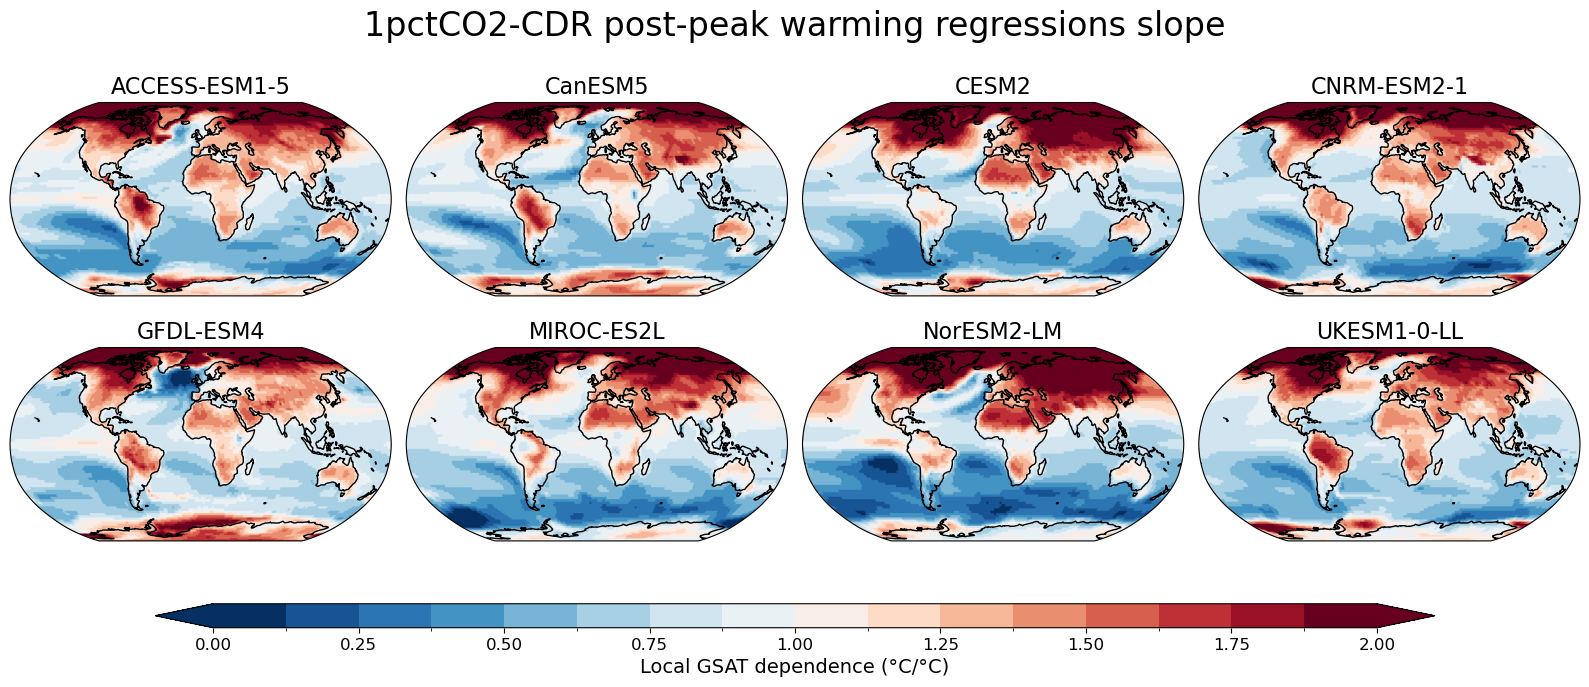

In [45]:
expt = '1pctCO2-CDR'
period = 'post-peak'
patterns = post_patterns
var = 'slope'
fig, axes = plt.subplots(
    2, 4,
    figsize=(16, 6),
    subplot_kw={'projection': ccrs.Robinson()}
)

levels = np.linspace(0,2,17)
cmap = cm.RdBu_r
norm = BoundaryNorm(levels, ncolors=cmap.N, clip=True)



for (model,ds_dict), ax in zip(patterns.items(),axes.flat):
    ds = ds_dict[var]
    im = ax.imshow(
        ds,
        transform=ccrs.PlateCarree(),
        cmap=cmap,
        norm=norm,
        origin='lower',
        extent=(0, 360, -90, 90),
    )
    ax.coastlines()
    ax.set_title(model, fontsize=16)

cbar_ax = fig.add_axes([0.1, -0.05, 0.8, 0.04])
cbar = fig.colorbar(
    plt.cm.ScalarMappable(norm=norm, cmap=cmap),
    cax=cbar_ax,
    orientation="horizontal",
    extend="both"
)
cbar.set_label('Local GSAT dependence (°C/°C)', fontsize=14)
# cbar.set_ticks([-1,-0.5,0,0.5,1])
cbar.ax.tick_params(labelsize=12)

fig.suptitle(f"{expt} {period} warming regressions {var}",fontsize=24)

fig.tight_layout()

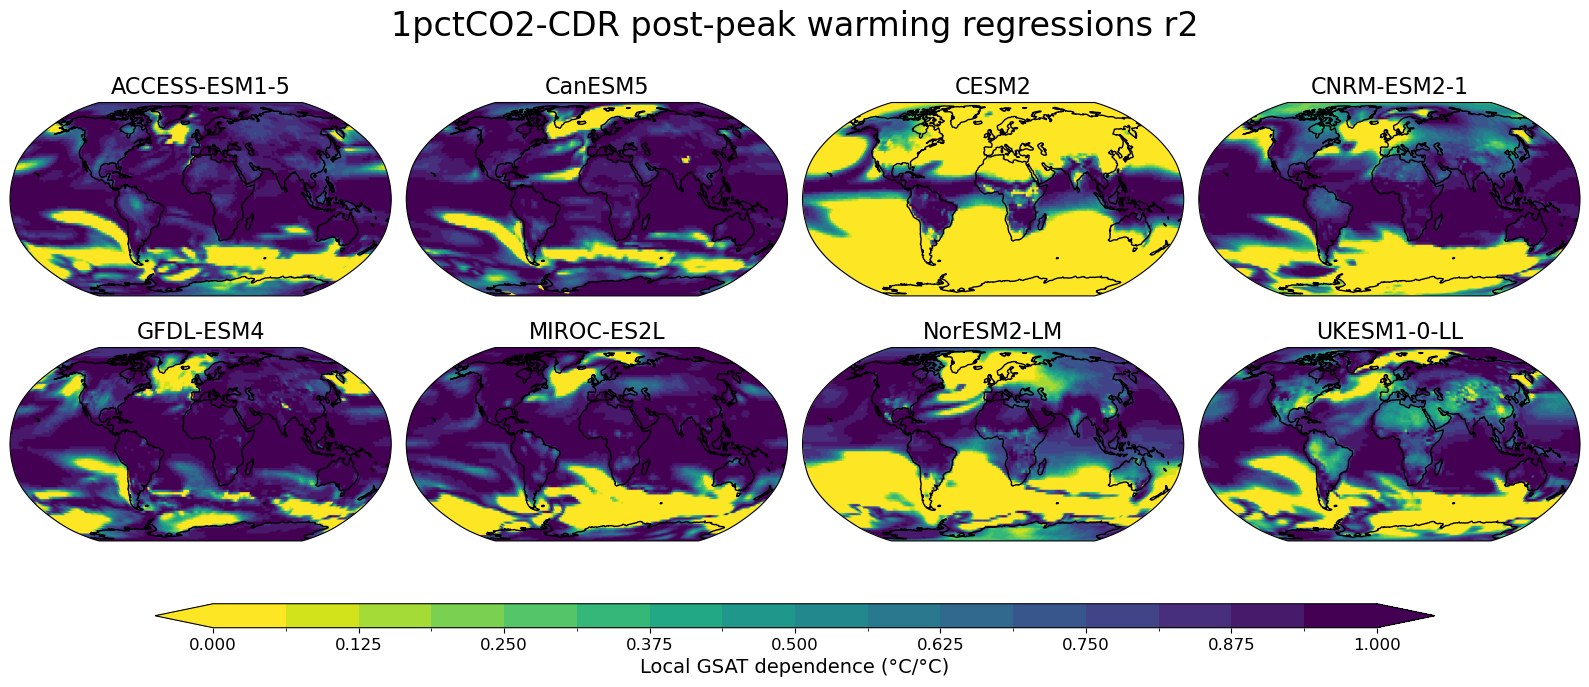

In [51]:
expt = '1pctCO2-CDR'
period = 'post-peak'
patterns = post_patterns
var = 'r2'
fig, axes = plt.subplots(
    2, 4,
    figsize=(16, 6),
    subplot_kw={'projection': ccrs.Robinson()}
)

levels = np.linspace(0,1,17)
cmap = cm.viridis_r
norm = BoundaryNorm(levels, ncolors=cmap.N, clip=True)



for (model,ds_dict), ax in zip(patterns.items(),axes.flat):
    ds = ds_dict[var]
    im = ax.imshow(
        ds,
        transform=ccrs.PlateCarree(),
        cmap=cmap,
        norm=norm,
        origin='lower',
        extent=(0, 360, -90, 90),
    )
    ax.coastlines()
    ax.set_title(model, fontsize=16)

cbar_ax = fig.add_axes([0.1, -0.05, 0.8, 0.04])
cbar = fig.colorbar(
    plt.cm.ScalarMappable(norm=norm, cmap=cmap),
    cax=cbar_ax,
    orientation="horizontal",
    extend="both"
)
cbar.set_label('Local GSAT dependence (°C/°C)', fontsize=14)
# cbar.set_ticks([-1,-0.5,0,0.5,1])
cbar.ax.tick_params(labelsize=12)

fig.suptitle(f"{expt} {period} warming regressions {var}",fontsize=24)

fig.tight_layout()

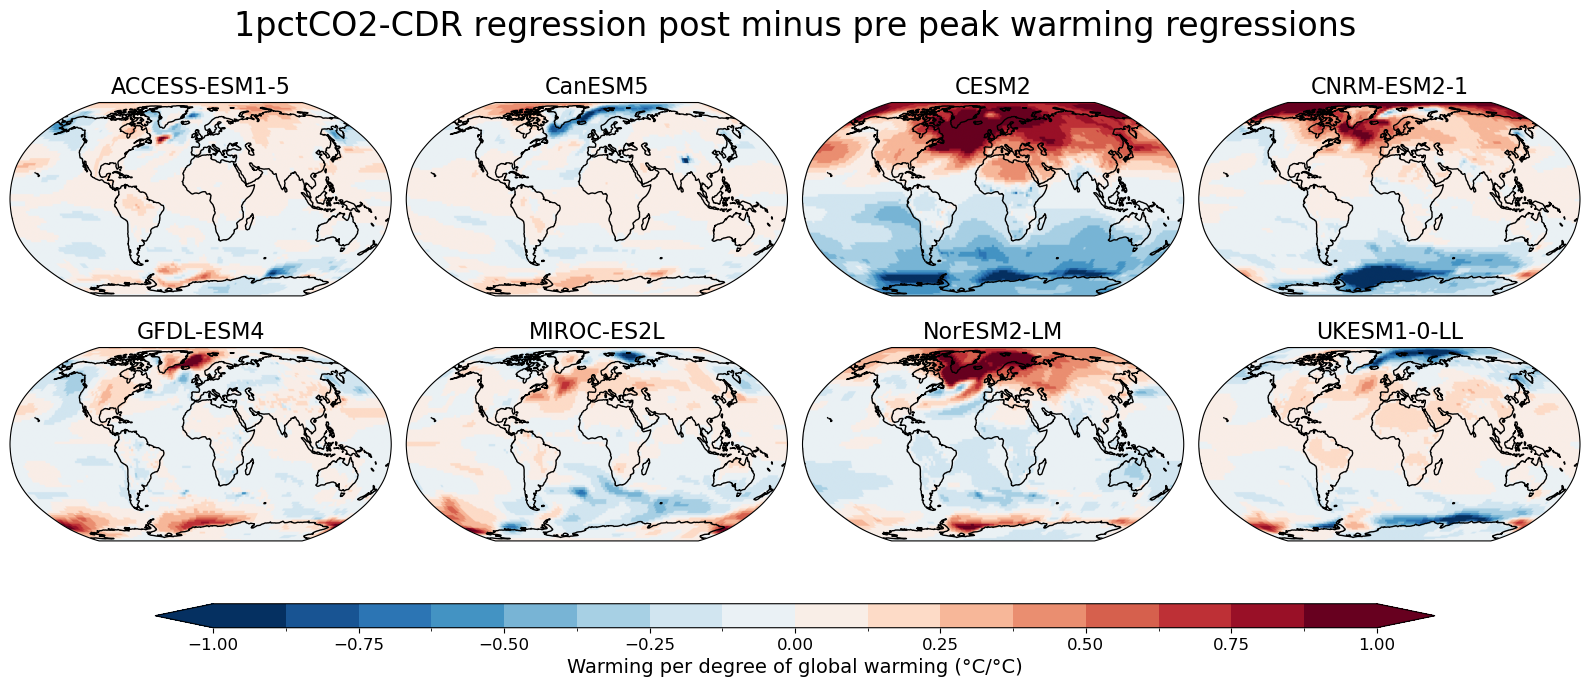

In [34]:
expt = '1pctCO2-CDR'
period = 'differences'
patterns = differences
fig, axes = plt.subplots(
    2, 4,
    figsize=(16, 6),
    subplot_kw={'projection': ccrs.Robinson()}
)

levels = np.linspace(-1,1,17)
cmap = cm.RdBu_r
norm = BoundaryNorm(levels, ncolors=cmap.N, clip=True)



for (model,ds), ax in zip(patterns.items(),axes.flat):
        
    im = ax.imshow(
        ds,
        transform=ccrs.PlateCarree(),
        cmap=cmap,
        norm=norm,
        origin='lower',
        extent=(0, 360, -90, 90),
    )
    ax.coastlines()
    ax.set_title(model, fontsize=16)

cbar_ax = fig.add_axes([0.1, -0.05, 0.8, 0.04])
cbar = fig.colorbar(
    plt.cm.ScalarMappable(norm=norm, cmap=cmap),
    cax=cbar_ax,
    orientation="horizontal",
    extend="both"
)
cbar.set_label('Change in local GSAT dependence (°C/°C)', fontsize=14)
# cbar.set_ticks([-1,-0.5,0,0.5,1])
cbar.ax.tick_params(labelsize=12)

fig.suptitle(f"{expt} regression post minus pre peak warming regressions",fontsize=24)

fig.tight_layout()

## Regional Analysis

In [11]:
zonal_avgs = {}
for model, ds in tas_rolling.items():
    ds = ds.tas
    zonal_avgs[model] = {
        'land': regions.get_zonal_averages(ds,mask=mask_ocean.topo),
        'ocean': regions.get_zonal_averages(ds,mask=mask_land.topo),
        'all': regions.get_zonal_averages(ds,mask=None)
    }

In [12]:
# calculate multi-model median
zonal_avgs['Multi-Model Median'] = {'land':{}, 'ocean':{}, 'all': {}}
for surface in ['land','ocean','all']:
    for region in regions.zonal_regions:
        all_models = [zonal_avgs[model][surface][region] for model in models]
        zonal_avgs['Multi-Model Median'][surface][region] = xr.concat(
            all_models,
            dim='model',
            compat='override',
            coords='minimal'
        ).median(dim='model')
        

In [13]:
gsat_median = xr.concat(
    list(gsat_rolling.values()),
    dim='model'
).median(dim='model')

# peak, peak_year = utils.peak_warming(gsat_median)
# peaks['Multi-Model Median'] = {'peak':peak,'peak_year':peak_year}
# gsat_rolling['Multi-Model Median'] = gsat_median

## Hysteresis plots

In [14]:
def plot_zonal_hysteresis(
        zonal_regions,
        zonal_avgs,
        surface,
        gsat_rolling,
        gsat_median,
        peaks,
        figsize=(16,8)
    ):

    fig = plt.figure(figsize=figsize)

    if len(zonal_regions) == 7:

        gs = fig.add_gridspec(2, 8)

        axes = [
            fig.add_subplot(gs[0, 0:2]),
            fig.add_subplot(gs[0, 2:4]),
            fig.add_subplot(gs[0, 4:6]),
            fig.add_subplot(gs[0, 6:8]),
            fig.add_subplot(gs[1, 1:3]),
            fig.add_subplot(gs[1, 3:5]),
            fig.add_subplot(gs[1, 5:7]),
        ]

    else:
        # fallback
        ncol = 4
        nrow = int(np.ceil(len(zonal_regions) / ncol))
        fig, axarr = plt.subplots(nrow, ncol, figsize=figsize)
        axes = axarr.flatten()

    for region, ax in zip(zonal_regions, axes):

        for model in zonal_avgs.keys():

            da = zonal_avgs[model][surface][region]

            if model == 'Multi-Model Median':
                gsat_da = gsat_median
                peak_year = utils.peak_warming(gsat_median)[1]
                linewidth = 2
            else:
                gsat_da = gsat_rolling[model]
                peak_year = peaks[model]['peak_year']
                linewidth = 1

            ax.plot(
                gsat_da.sel(year=slice(None, peak_year)),
                da.sel(year=slice(None, peak_year)),
                color=colour_dict[model],
                label=model,
                linewidth=linewidth
            )

            ax.plot(
                gsat_da.sel(year=slice(peak_year, 339)),
                da.sel(year=slice(peak_year, 339)),
                color=colour_dict[model],
                linestyle='--',
                linewidth=linewidth
            )

        ax.set_title(region, fontsize=16)
        ax.set_xlabel('GSAT (°C)', fontsize=14)
        ax.set_ylabel('Regional SAT (°C)', fontsize=14)
        ax.tick_params(axis='both', labelsize=12)
        ax.grid()

    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc='lower center',
        bbox_to_anchor=(0.5, -0.1),
        ncol=5,
        fontsize=16,
        frameon=False
    )

    fig.suptitle(
        f'Zonal average {surface} SAT versus GSAT',
        fontsize=24
    )

    fig.tight_layout()

    return fig

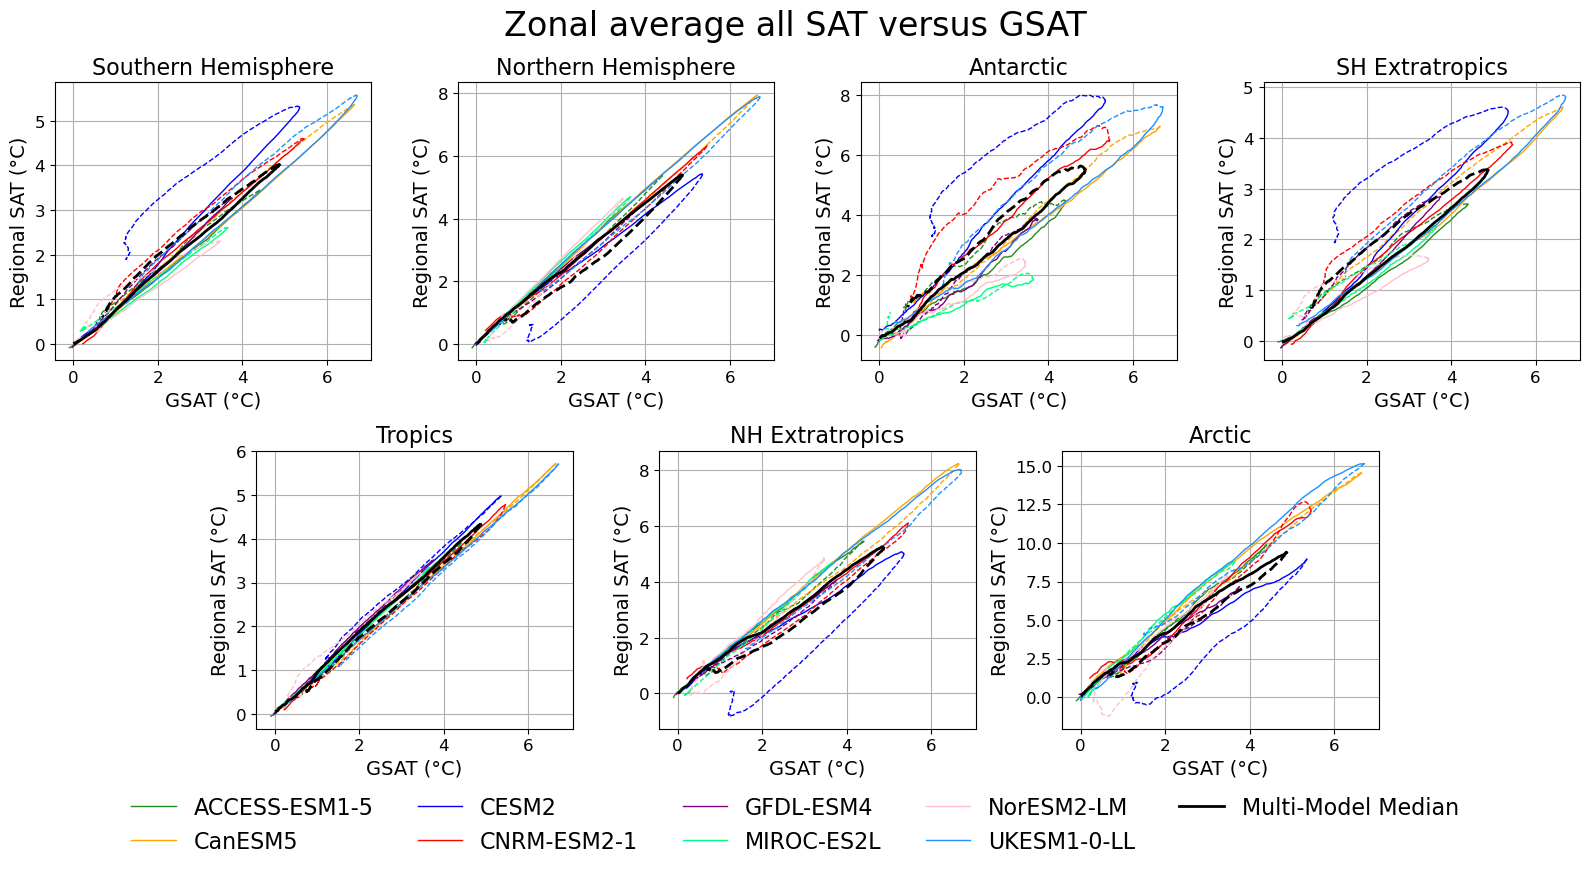

In [15]:
fig = plot_zonal_hysteresis(
    regions.zonal_regions,
    zonal_avgs,
    'all',
    gsat_rolling,
    gsat_median,
    peaks,
    # 2,
    # 4,
    (16,8)
)
    

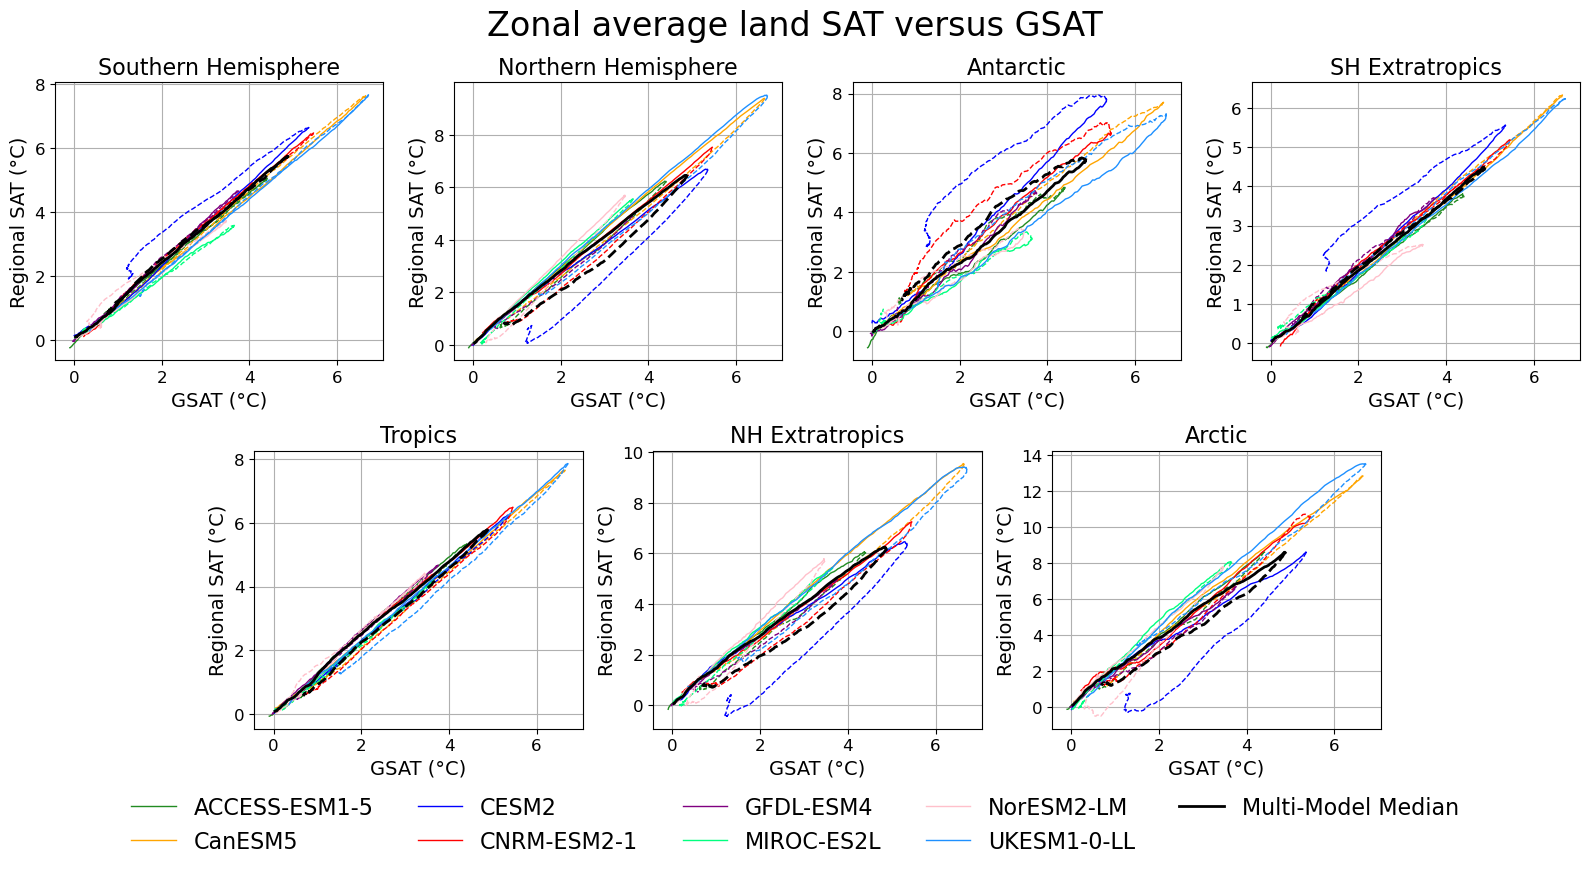

In [16]:
fig = plot_zonal_hysteresis(
    regions.zonal_regions,
    zonal_avgs,
    'land',
    gsat_rolling,
    gsat_median,
    peaks,
    # 2,
    # 4,
    (16,8)
)
    

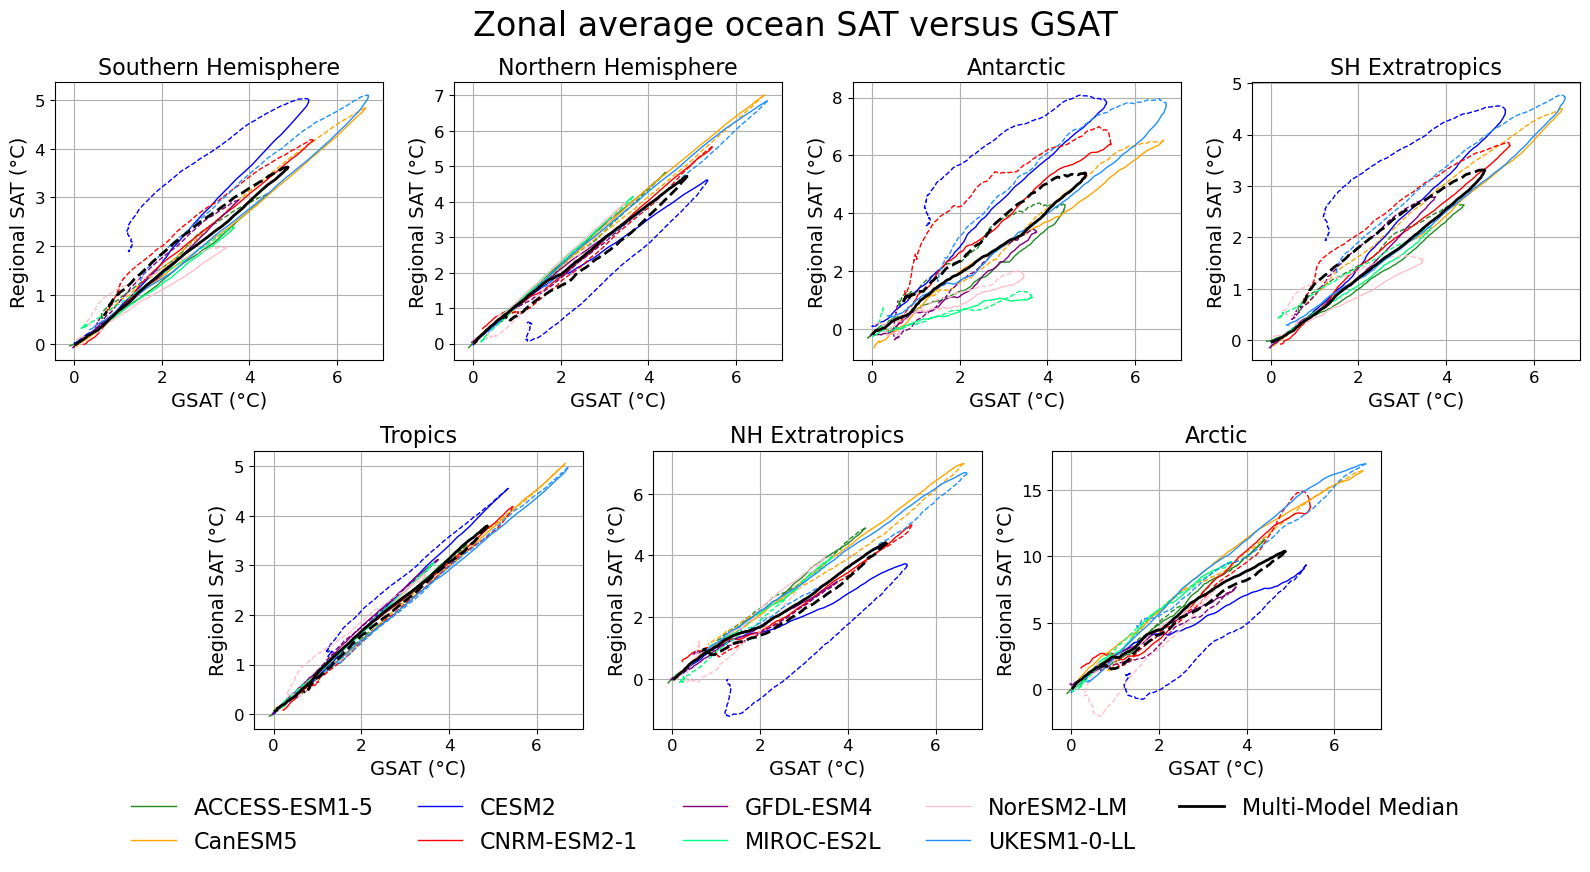

In [17]:
fig = plot_zonal_hysteresis(
    regions.zonal_regions,
    zonal_avgs,
    'ocean',
    gsat_rolling,
    gsat_median,
    peaks,
    # 2,
    # 4,
    (16,8)
)
    

## Plot timeseries

In [18]:
# load co2 series
path = os.path.join(data_dir,'processed/co2/co2.nc')
CO2 = xr.open_dataset(path).rename(
    {'__xarray_dataarray_variable__':'CO2'}
).CO2


In [27]:
def plot_zonal_timeseries(model,surface,gsat_da,zonal_avgs):
    fig, ax = plt.subplots(1,1,figsize=(12,4))
    
    to_plot = zonal_avgs[model][surface]
    
    for region, ds in to_plot.items():
        ds.plot(
            ax=ax,
            label=region,
            linewidth=1.5,
        )
    
    gsat_da.plot(
        ax=ax,
        label='GSAT',
        color='black',
        linewidth='4',
    )
    
    ax.set_ylabel('Zonal Average SAT (°C)', fontsize=14)
    ax.set_xlim([0,345])
    ax.set_ylim([-1,11])
    x_ticks = [0,140,280,340]  # Add 340 to the list of x-ticks
    x_tick_labels = ['0','140','280','340']  # Corresponding tick labels
    ax.set_xticks(x_ticks)
    ax.set_xticklabels(x_tick_labels,fontsize=16)
    ax.set_xlabel('Year',fontsize=18)
    ax.axvline(x = 140, color = 'gray',linewidth=1.0,linestyle='--',alpha=0.7)
    ax.axvline(x = 280, color = 'gray',linewidth=1.0,linestyle='--',alpha=0.7)
    ax.axhline(y = 0, color = 'black',linewidth=1.0)
        
    
    ax2 = ax.twinx()
    co2_line = ax2.plot(CO2[100:],
                        label='Atmospheric CO$_2$',
                         color='gray',
                         linewidth=2,
                         linestyle='--',
                         alpha=0.7
                       )
    ax2.set_ylabel('Atmospheric CO$_2$ (ppm)',fontsize=18,color='gray')
    ax2.tick_params(axis='y', colors='gray')                # Gray ticks and tick marks
    ax2.yaxis.label.set_color('gray')  
    
    ax.tick_params(axis='y', labelsize=16)    # For the main y-axis (GSAT)
    ax2.tick_params(axis='y', labelsize=16) 
    
    handles, labels = ax.get_legend_handles_labels()
        # Append the CO₂ line to the legend
    
    handles2,labels2 = ax2.get_legend_handles_labels()
    # labels2 = []
    # handles2.append(co2_line[0])
    # labels2.append('Atmospheric CO$_2$')
    
    
    # Create a legend below all subplots
    ax.legend(handles, labels, loc='upper left', 
              # bbox_to_anchor=(0.5, -0.1), 
              ncol=1, fontsize=12,frameon=False)
    ax2.legend(handles2,labels2,loc='upper right',ncol=1,fontsize=12,frameon=False)
    
    fig.suptitle(f"{model} {surface.capitalize()} SAT",fontsize=20)
    fig.tight_layout()
    

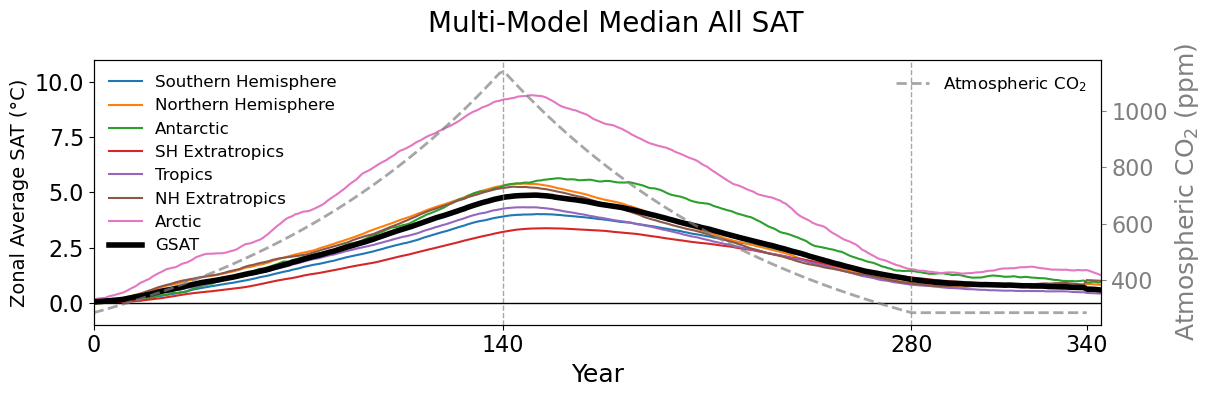

In [28]:
plot_zonal_timeseries(
    'Multi-Model Median',
    'all',
    gsat_median,
    zonal_avgs
)

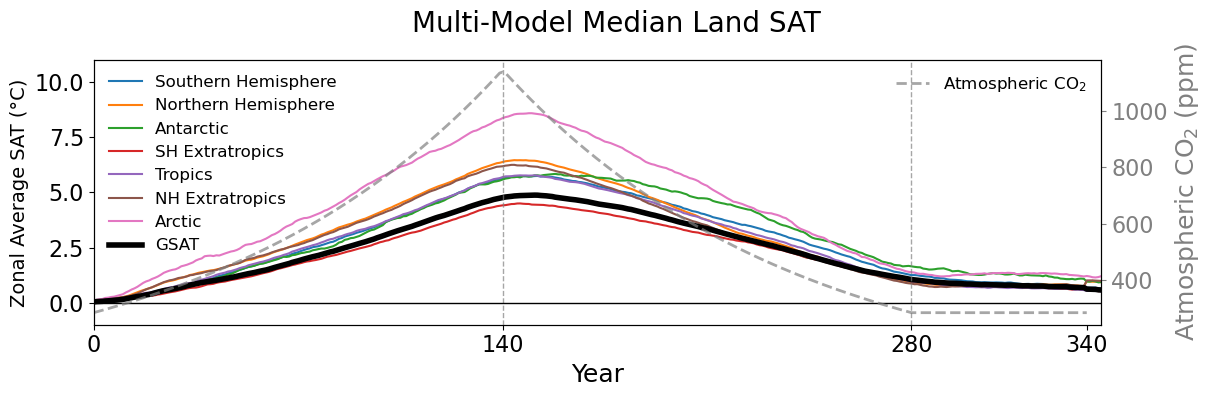

In [29]:
plot_zonal_timeseries(
    'Multi-Model Median',
    'land',
    gsat_median,
    zonal_avgs
)

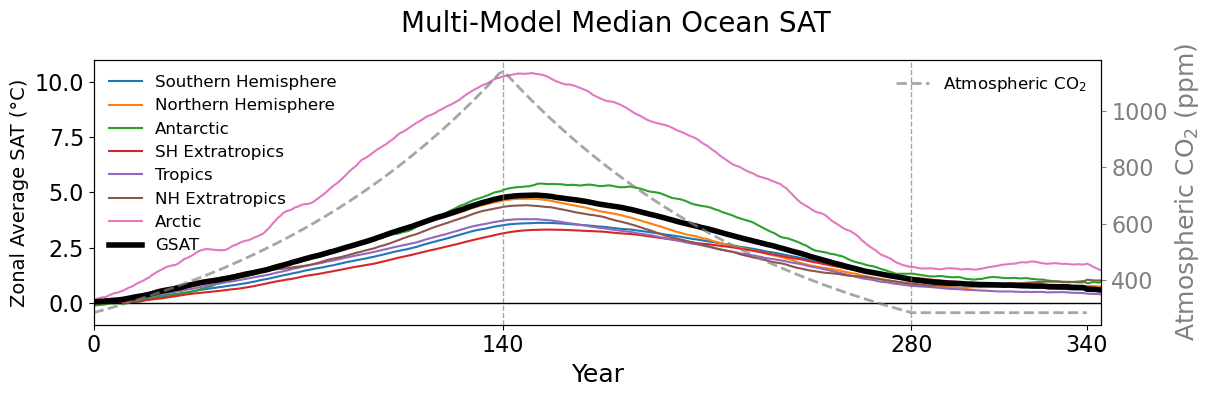

In [30]:
plot_zonal_timeseries(
    'Multi-Model Median',
    'ocean',
    gsat_median,
    zonal_avgs
)

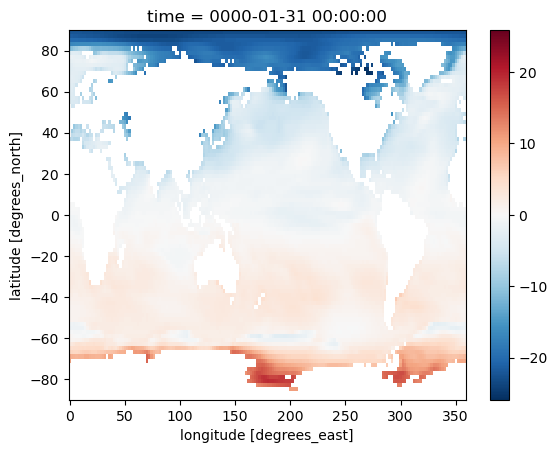

In [34]:
(tas_anom['ACCESS-ESM1-5'].tas * mask_land.topo).isel(time=0).plot()